In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)

BASE = Path(r"C:\Users\Zerlina\Documents\PENS\SEMESTER 5\AGRIDASH 1.0")
DIRS = {"clean": BASE / "data" / "clean" / "hortikultura",
        "model_ready": BASE / "data" / "model_ready",
        "eda": BASE / "outputs" / "eda",
        "reports": BASE / "outputs" / "reports"}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

clean = pd.read_csv(DIRS["clean"] / "hortikultura_kecamatan_clean.csv", encoding="utf-8-sig")
kab = pd.read_csv(DIRS["clean"] / "hortikultura_kabupaten_clean.csv", encoding="utf-8-sig")
COMPLETE_YEARS = sorted(clean.loc[clean["tahun_lengkap"], "tahun"].unique().tolist())
TON = 1000
print("kecamatan:", clean.shape, "| kabupaten:", kab.shape, "| tahun lengkap:", COMPLETE_YEARS)

kecamatan: (8268, 9) | kabupaten: (318, 8) | tahun lengkap: [2020, 2021, 2022, 2023, 2024, 2025]


seri waktu dan metode

In [2]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
warnings.filterwarnings("ignore")
years = sorted(COMPLETE_YEARS)
H = 2
fallback = {"n": 0}

def f_naive(y, h):  return np.repeat(y[-1], h)
def f_linear(y, h): return np.polyval(np.polyfit(np.arange(len(y)), y, 1), np.arange(len(y), len(y) + h))
def f_ets(y, h):
    try:    return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h)
    except Exception: fallback["n"] += 1; return f_naive(y, h)
def f_ets_trend(y, h):
    try:    return ExponentialSmoothing(y, trend="add", damped_trend=True, initialization_method="estimated").fit().forecast(h)
    except Exception: fallback["n"] += 1; return f_naive(y, h)
METHODS = {"naive (tahun lalu)": f_naive, "ETS sederhana": f_ets, "ETS tren teredam": f_ets_trend, "regresi linear": f_linear}
FORECAST_METHOD = "ETS sederhana"

def build_series(df, keys, value):
    p = df[df["tahun"].isin(years)].pivot(index=keys, columns="tahun", values=value)[years]
    return p[(p.notna().all(axis=1)) & (p > 0).all(axis=1)]
SERIES = {}
for target in ["produksi", "luas"]:
    SERIES[("kabupaten", target)] = build_series(kab, "komoditas", target)
    SERIES[("kecamatan", target)] = build_series(clean, ["kecamatan", "komoditas"], target)
for k, v in SERIES.items():
    total = clean.groupby(["kecamatan", "komoditas"]).ngroups if k[0] == "kecamatan" else kab["komoditas"].nunique()
    print(f"Seri {k[0]:9s} | {k[1]:8s}: dipakai {len(v)} dari {total}")

Seri kabupaten | produksi: dipakai 42 dari 53
Seri kecamatan | produksi: dipakai 358 dari 1378
Seri kabupaten | luas    : dipakai 42 dari 53
Seri kecamatan | luas    : dipakai 358 dari 1378


backtest

Seri gagal di-fit (cadangan naive): 0


model               ETS sederhana  ETS tren teredam  naive (tahun lalu)  regresi linear
level     target                                                                       
kabupaten luas               7.18              9.34                7.87            8.71
          produksi          10.07             18.17               12.31           14.12
kecamatan luas              11.07             15.25               12.72           14.41
          produksi          11.74             19.92               14.29           16.65

kabupaten | luas     -> terbaik: ETS sederhana (7.18%) | ETS sederhana: 7.18% | naive: 7.87%
kabupaten | produksi -> terbaik: ETS sederhana (10.07%) | ETS sederhana: 10.07% | naive: 12.31%
kecamatan | luas     -> terbaik: ETS sederhana (11.07%) | ETS sederhana: 11.07% | naive: 12.72%
kecamatan | produksi -> terbaik: ETS sederhana (11.74%) | ETS sederhana: 11.74% | naive: 14.29%


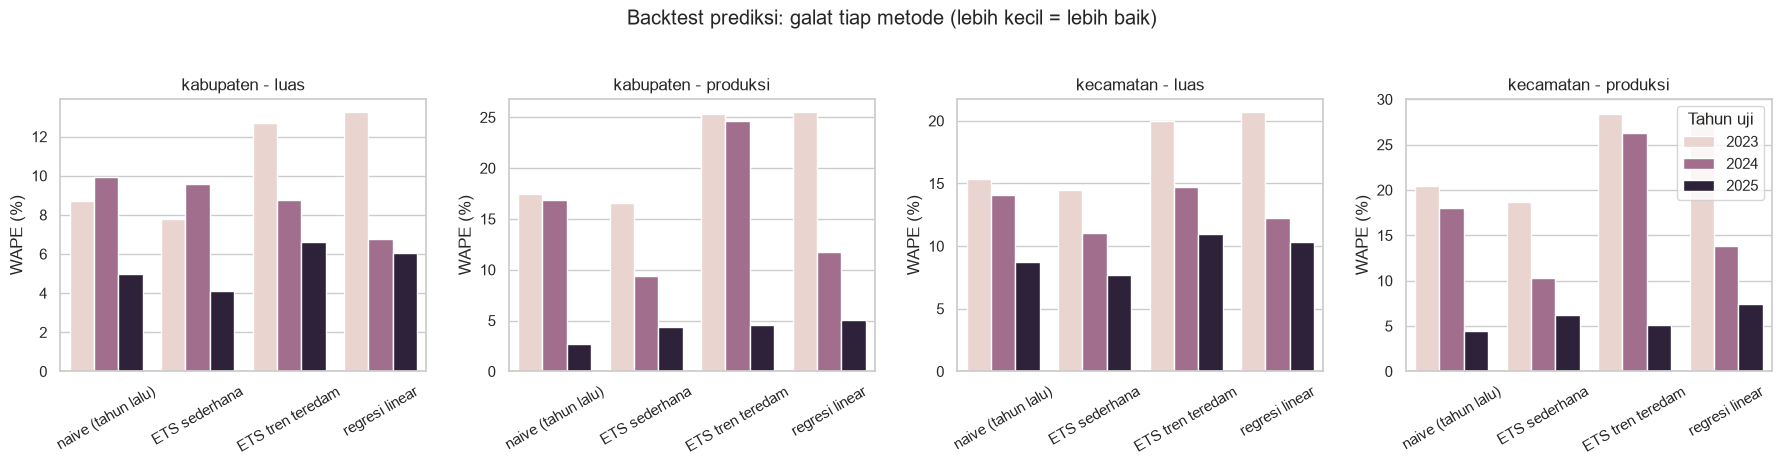

In [3]:
rows = []
for (level, target), P in SERIES.items():
    for origin in range(3, len(years)):
        actual = P[years[origin]].values
        for mname, fn in METHODS.items():
            pred = np.clip(np.array([fn(r[:origin].astype(float), 1)[0] for r in P[years[:origin]].values]), 0, None)
            rows.append({"level": level, "target": target, "uji_tahun": years[origin], "n_latih_tahun": origin, "model": mname,
                         "n_seri": len(P), "MAE": np.abs(actual - pred).mean(),
                         "WAPE_%": 100 * np.abs(actual - pred).sum() / actual.sum(),
                         "MdAPE_%": 100 * np.median(np.abs(actual - pred) / actual)})
bt = pd.DataFrame(rows).round(3)
bt.to_csv(DIRS["reports"] / "backtest_forecast_hortikultura.csv", index=False)
print("Seri gagal di-fit (cadangan naive):", fallback["n"])
summary = bt.groupby(["level", "target", "model"])["WAPE_%"].mean().round(2).unstack("model")
display(summary)
for (level, target), r in summary.iterrows():
    print(f"{level:9s} | {target:8s} -> terbaik: {r.idxmin()} ({r.min():.2f}%) | {FORECAST_METHOD}: {r[FORECAST_METHOD]:.2f}% | naive: {r['naive (tahun lalu)']:.2f}%")

fig, ax = plt.subplots(1, 4, figsize=(18, 4.5))
for a, ((level, target), g) in zip(ax, bt.groupby(["level", "target"])):
    sns.barplot(data=g, x="model", y="WAPE_%", hue="uji_tahun", ax=a)
    a.set_title(f"{level} - {target}"); a.set_xlabel(""); a.set_ylabel("WAPE (%)"); a.tick_params(axis="x", rotation=30)
    if a is not ax[-1]: a.get_legend().remove()
ax[-1].legend(title="Tahun uji"); fig.suptitle("Backtest prediksi: galat tiap metode (lebih kecil = lebih baik)", y=1.03)
plt.tight_layout(); fig.savefig(DIRS["eda"] / "f2_backtest.png", dpi=130, bbox_inches="tight"); plt.show()

prediksi 2026–2027

Prediksi tersimpan: (1600, 11)


tahun                                    2026         2027  aktual_terakhir
kelompok komoditas                                                         
buah     Alpukat                   22817092.0   22817092.0       22817092.0
         Belimbing                  4295400.0    4295400.0        4485712.0
         Buah Naga                   555439.0     555439.0         512200.0
         Duku/Langsat/Kokosan          9884.0       9884.0           4300.0
         Durian                    19073499.0   19073499.0       20230648.0
         Jambu Air                  1984638.0    1984638.0        2176293.0
         Jambu Biji                 1485400.0    1485400.0        1628751.0
         Jengkol                      23477.0      23477.0          11550.0
         Jeruk Besar                   7445.0       7445.0           4025.0
         Jeruk Lemon                 533086.0     533086.0         533086.0
         Jeruk Siam/Keprok         11409025.0   11409025.0       11226750.0
         Lengkeng                    722451.0     722451.0         778189.0
         Mangga                    83464204.0   83464204.0       83476171.0
         Manggis                     651299.0     651299.0         653700.0
         Melinjo                    5947685.0    5947685.0        6394211.0
         Nangka/Cempedak            4705039.0    4705039.0        4705039.0
         Nenas                    403947982.0  403947982.0      424894623.0
         Pepaya                     5744649.0    5744649.0        5916400.0
         Petai                      3304357.0    3304357.0        3304357.0
         Pisang                    61935800.0   61935800.0       62222284.0
         Rambutan                   6010519.0    6010519.0        5957350.0
         Salak                       252453.0     252453.0         239660.0
         Sawo                       1570401.0    1570401.0        1570401.0
         Sirsak                     4382012.0    4382012.0        4382012.0
         Sukun                       451975.0     451975.0         451975.0
sayur    Bawang Daun                4426400.0    4426400.0        4426400.0
         Bawang Merah               8116653.0    8116653.0        8360200.0
         Bayam                       470013.0     470013.0         439000.0
         Buncis                     2024394.0    2024394.0        2094000.0
         Cabai Besar/TW/Teropong   13964808.0   13964808.0       13743950.0
         Cabai Keriting             5483430.0    5483430.0        5483430.0
         Cabai Rawit              109470944.0  109470944.0      109561361.0
         Jamur Tiram                 699776.0     699776.0         702960.0
         Kacang Panjang             4418827.0    4418827.0        4780645.0
         Kangkung                    462368.0     462368.0         453300.0
         Kembang Kol                2361150.0    2361150.0        2361150.0
         Ketimun                    6495554.0    6495554.0        6810930.0
         Melon                       935493.0     935493.0         934900.0
         Petsai/Sawi                3413781.0    3413781.0        3413875.0
         Semangka                   1670924.0    1670924.0        1743200.0
         Terung                    10028427.0   10028427.0       10823544.0
         Tomat                      7017209.0    7017209.0        7599935.0

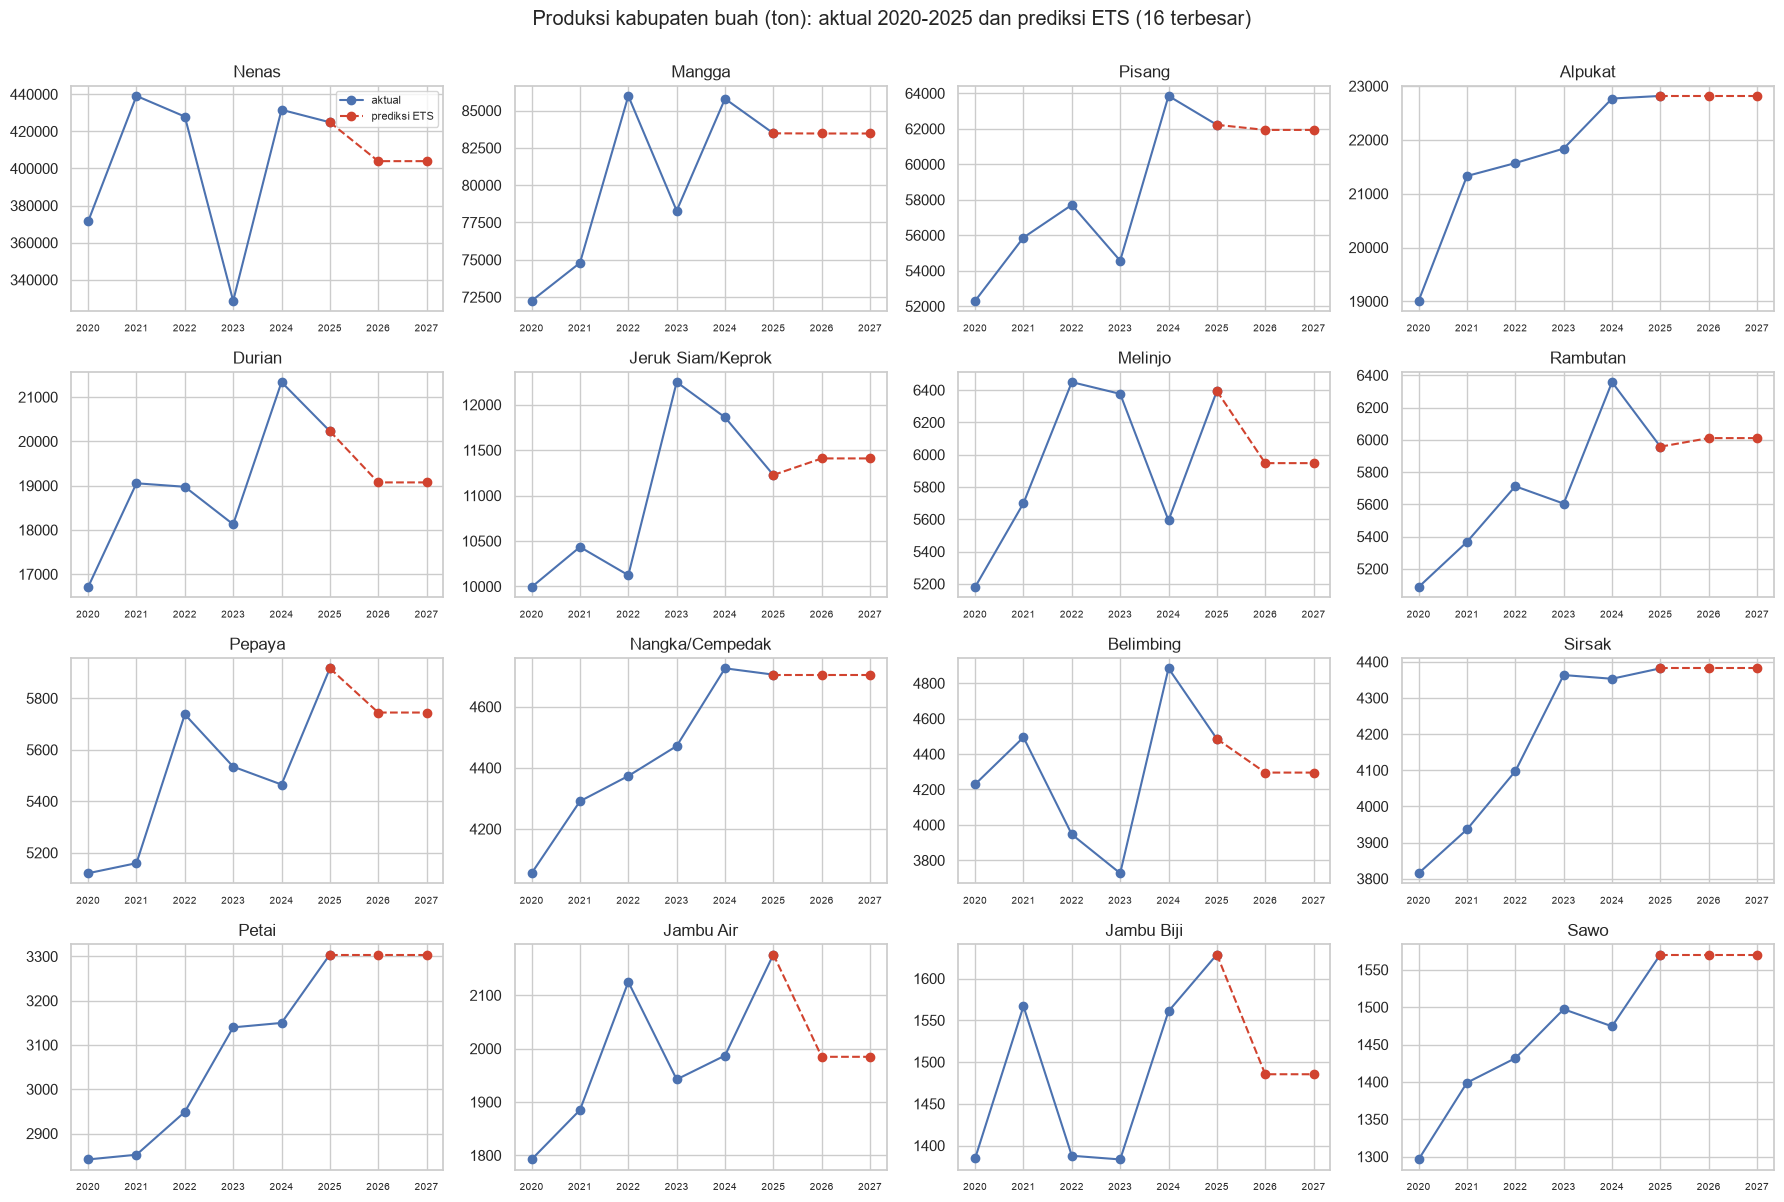

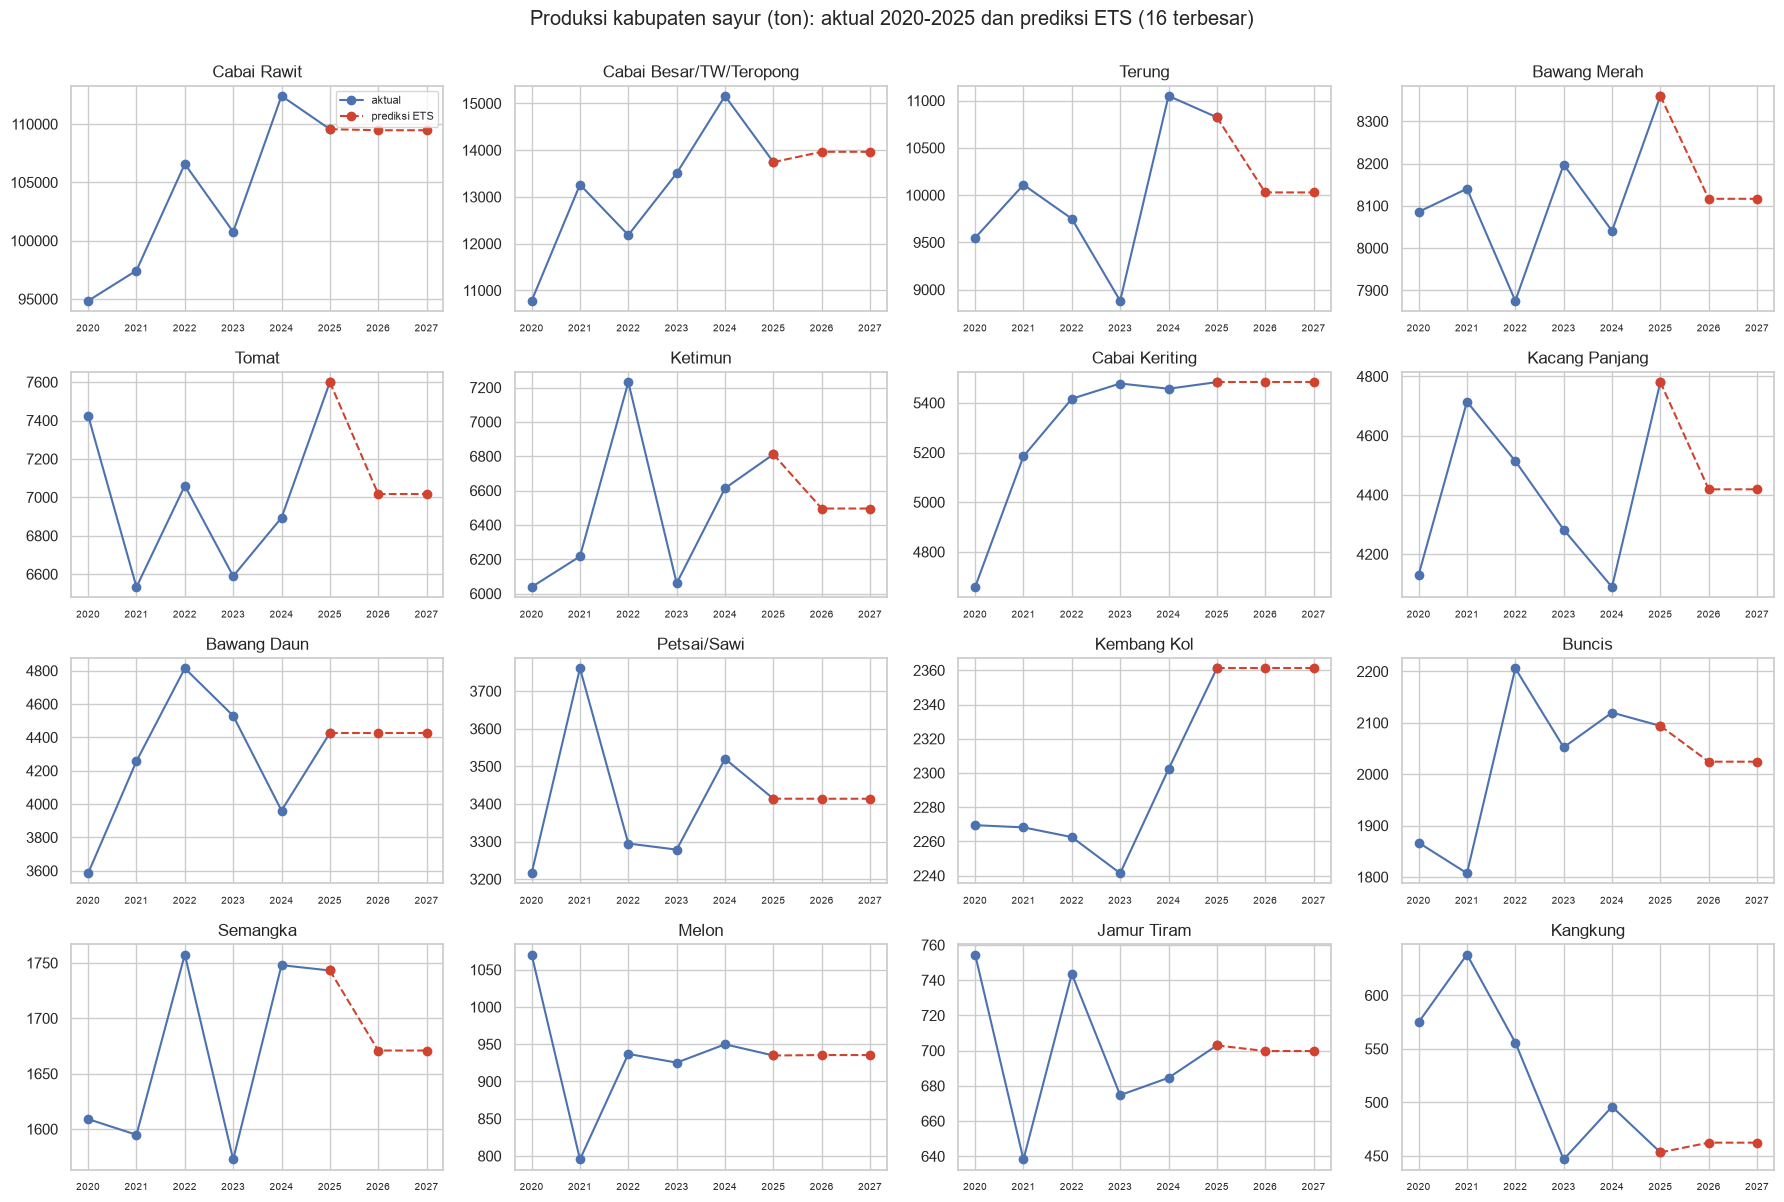

In [4]:
fc_rows = []
for (level, target), P in SERIES.items():
    wape = summary.loc[(level, target), FORECAST_METHOD]
    for idx, r in P.iterrows():
        y = r.values.astype(float); f = np.clip(METHODS[FORECAST_METHOD](y, H), 0, None)
        keys = {"komoditas": idx} if level == "kabupaten" else {"kecamatan": idx[0], "komoditas": idx[1]}
        for i in range(H):
            fc_rows.append({"level": level, "target": target, **keys, "tahun": years[-1] + 1 + i, "prediksi": f[i],
                            "aktual_terakhir": y[-1], "perubahan_vs_terakhir_%": 100 * (f[i] / y[-1] - 1), "galat_backtest_WAPE_%": wape})
fc = pd.DataFrame(fc_rows)
kel_map = kab.drop_duplicates("komoditas").set_index("komoditas")["kelompok"]
unit_map = kab.drop_duplicates("komoditas").set_index("komoditas")["unit_luas"]
fc["kelompok"] = fc["komoditas"].map(kel_map)
fc["unit"] = np.where(fc["target"] == "produksi", "kg", fc["komoditas"].map(unit_map))
fc.round(3).to_csv(DIRS["model_ready"] / "prediksi_ets_hortikultura.csv", index=False)
print("Prediksi tersimpan:", fc.shape)
kp = fc[(fc.level == "kabupaten") & (fc.target == "produksi")]
display(kp.pivot(index=["kelompok", "komoditas"], columns="tahun", values="prediksi")
          .assign(aktual_terakhir=kp.groupby(["kelompok", "komoditas"])["aktual_terakhir"].first()).round(0))

hist = SERIES[("kabupaten", "produksi")]
for kel in ["buah", "sayur"]:
    ks = [k for k in hist.index if kel_map[k] == kel]
    ks = hist.loc[ks].iloc[:, -1].sort_values(ascending=False).index[:16]
    fig, axes = plt.subplots(4, 4, figsize=(18, 12))
    for a, kom in zip(axes.ravel(), ks):
        a.plot(years, hist.loc[kom].values / TON, "o-", label="aktual"); f = kp[kp.komoditas == kom]
        a.plot([years[-1]] + f["tahun"].tolist(), [hist.loc[kom].values[-1] / TON] + (f["prediksi"] / TON).tolist(), "o--", c="#d1432f", label="prediksi ETS")
        a.set_title(kom); a.set_xticks(years + f["tahun"].tolist()); a.tick_params(axis="x", labelsize=7)
    for a in axes.ravel()[len(ks):]: a.axis("off")
    axes[0, 0].legend(fontsize=8); fig.suptitle(f"Produksi kabupaten {kel} (ton): aktual {years[0]}-{years[-1]} dan prediksi ETS (16 terbesar)", y=1.0)
    plt.tight_layout(); fig.savefig(DIRS["eda"] / f"f3_prediksi_{kel}.png", dpi=130, bbox_inches="tight"); plt.show()

evaluasi jumlah klaster

Profil klaster: (26, 53) (kecamatan x komoditas, rata-rata produksi kg/tahun 2020-2025)


,metode,k,silhouette,davies_bouldin,klaster_terkecil,ukuran
0,KMeans,2,0.118,2.355,7,"[7, 19]"
1,Agglomerative,2,0.118,2.355,7,"[19, 7]"
2,KMeans,3,0.108,1.762,1,"[7, 18, 1]"
3,Agglomerative,3,0.108,2.080,2,"[7, 17, 2]"
4,KMeans,4,0.032,2.573,3,"[8, 4, 11, 3]"
5,Agglomerative,4,0.102,1.855,2,"[17, 5, 2, 2]"
6,KMeans,5,0.038,2.086,2,"[4, 5, 13, 2, 2]"
7,Agglomerative,5,0.061,1.947,2,"[5, 13, 2, 2, 4]"
8,KMeans,6,0.029,2.057,2,"[5, 6, 2, 4, 2, 7]"
9,Agglomerative,6,0.068,1.768,2,"[13, 2, 2, 3, 4, 2]"


K dipilih = 2


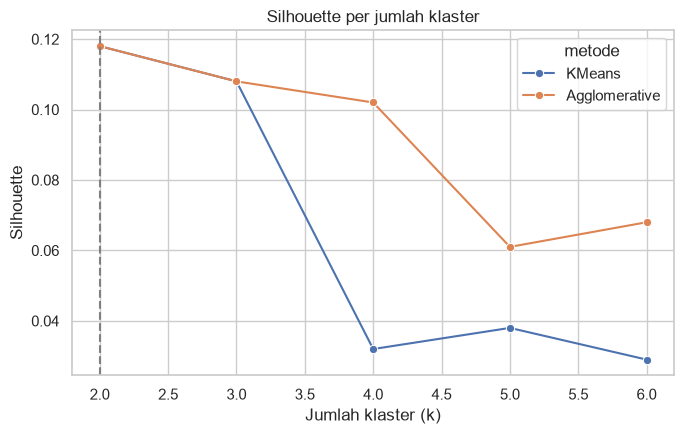

In [5]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

prof = (clean[clean["tahun"].isin(years)].pivot_table(index="kecamatan", columns="komoditas", values="produksi", aggfunc="mean")
        .fillna(0))                                  # tidak ada laporan = 0 HANYA untuk profil klaster
prof = prof.loc[:, prof.sum() > 0]
X = StandardScaler().fit_transform(np.log1p(prof))
print("Profil klaster:", prof.shape, f"(kecamatan x komoditas, rata-rata produksi kg/tahun {years[0]}-{years[-1]})")

rows = []
for k in range(2, 7):
    for name, lab in [("KMeans", KMeans(k, n_init=50, random_state=42).fit_predict(X)),
                      ("Agglomerative", AgglomerativeClustering(k, linkage="ward").fit_predict(X))]:
        rows.append({"metode": name, "k": k, "silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab),
                     "klaster_terkecil": np.bincount(lab).min(), "ukuran": np.bincount(lab).tolist()})
ev = pd.DataFrame(rows).round(3); display(ev)
ev.to_csv(DIRS["reports"] / "evaluasi_klaster_hortikultura.csv", index=False)

K_OVERRIDE = None
ok = ev[(ev["metode"] == "KMeans") & (ev["klaster_terkecil"] >= 2)]
K_FINAL = K_OVERRIDE or int(ok.sort_values("silhouette", ascending=False).iloc[0]["k"])
print(f"K dipilih = {K_FINAL}")

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.lineplot(data=ev, x="k", y="silhouette", hue="metode", marker="o", ax=ax)
ax.axvline(K_FINAL, ls="--", c="gray")
ax.set_title("Silhouette per jumlah klaster"); ax.set_xlabel("Jumlah klaster (k)"); ax.set_ylabel("Silhouette")
plt.tight_layout(); fig.savefig(DIRS["eda"] / "c1_silhouette.png", dpi=130, bbox_inches="tight"); plt.show()

klaster akhir

Kesepakatan KMeans vs Agglomerative (ARI): 1.0


,jumlah,produksi_rata2,porsi_total,anggota
klaster,,,,
1,7,82532264.5,70.0,"Ngancar, Kepung, Puncu, Plosoklaten, Kandangan..."
2,19,13043469.4,30.0,"Tarokan, Banyakan, Ringinrejo, Grogol, Pagu, K..."


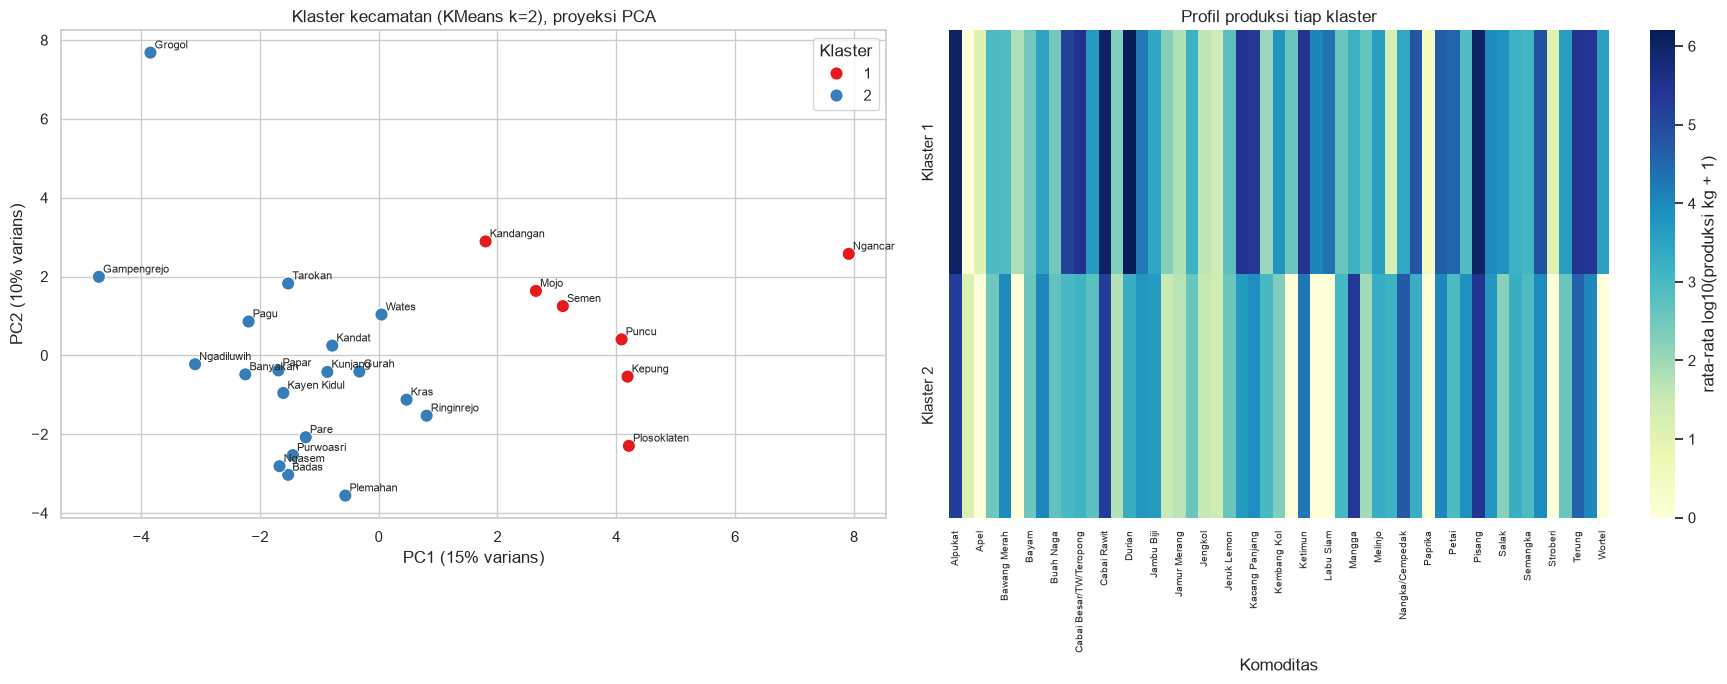

In [6]:
km = KMeans(K_FINAL, n_init=50, random_state=42).fit(X); ag = AgglomerativeClustering(K_FINAL, linkage="ward").fit(X)
total = prof.sum(axis=1)
res_cl = pd.DataFrame({"kecamatan": prof.index, "klaster_kmeans": km.labels_, "klaster_agglo": ag.labels_,
                       "produksi_rata2_kg_per_tahun": total.values, "porsi_kabupaten_%": 100 * total.values / total.sum()})
order = res_cl.groupby("klaster_kmeans")["produksi_rata2_kg_per_tahun"].mean().sort_values(ascending=False).index
rank = {c: i + 1 for i, c in enumerate(order)}; res_cl["klaster"] = res_cl["klaster_kmeans"].map(rank)    # 1 = produksi tertinggi
res_cl["top3_komoditas"] = [", ".join(prof.loc[k].sort_values(ascending=False).index[:3]) for k in res_cl["kecamatan"]]
res_cl = res_cl.sort_values(["klaster", "produksi_rata2_kg_per_tahun"], ascending=[True, False]).round(2)
res_cl.to_csv(DIRS["reports"] / "klaster_kecamatan_hortikultura.csv", index=False)
print("Kesepakatan KMeans vs Agglomerative (ARI):", round(adjusted_rand_score(km.labels_, ag.labels_), 3))
display(res_cl.groupby("klaster").agg(jumlah=("kecamatan", "size"), produksi_rata2=("produksi_rata2_kg_per_tahun", "mean"),
                                      porsi_total=("porsi_kabupaten_%", "sum"), anggota=("kecamatan", lambda s: ", ".join(s))).round(1))

pca = PCA(2, random_state=42).fit(X); Z = pca.transform(X); lab_rank = pd.Series(km.labels_).map(rank).values
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=lab_rank, palette="Set1", s=90, ax=ax[0])
for (x_, y_), n in zip(Z, prof.index): ax[0].annotate(n, (x_, y_), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax[0].set_title(f"Klaster kecamatan (KMeans k={K_FINAL}), proyeksi PCA"); ax[0].set_xlabel(f"PC1 ({100*pca.explained_variance_ratio_[0]:.0f}% varians)")
ax[0].set_ylabel(f"PC2 ({100*pca.explained_variance_ratio_[1]:.0f}% varians)"); ax[0].legend(title="Klaster")
cp = np.log10(prof + 1).groupby(lab_rank).mean(); cp.index = [f"Klaster {i}" for i in cp.index]
sns.heatmap(cp, cmap="YlGnBu", ax=ax[1], cbar_kws={"label": "rata-rata log10(produksi kg + 1)"}); ax[1].set_title("Profil produksi tiap klaster"); ax[1].set_xlabel("Komoditas")
ax[1].tick_params(axis="x", labelsize=7)
plt.tight_layout(); fig.savefig(DIRS["eda"] / "c2_klaster.png", dpi=130, bbox_inches="tight"); plt.show()